# Port of embarkation and survival

Passengers boarded at Southampton (S), Cherbourg (C) or Queenstown (Q). Survival rates differ by port, but the ports also differ in who boarded: class, sex, fare and family mix. The question is whether port is related to survival **after** those are allowed for.

**How it is tested**, from simplest to strictest:

1. **Raw survival by port**, with a chi-squared test.
2. **Who boarded where**: class and sex mix by port, which could explain the raw gap.
3. **Survival by port within class and sex**, and a **Cochran-Mantel-Haenszel test**: compares ports within each class and sex group, then pools the groups.
4. **Logistic regression, adding controls one at a time**: the odds ratio for Cherbourg and Queenstown against Southampton as class, sex, age, family, fare, title and deck enter. If the odds ratio moves to 1, the other features explain the port gap.
5. **Likelihood-ratio tests**: does adding port to the full model improve its fit by more than chance? Does port matter differently by class or by sex (interactions)?
6. **Cross-validation**: does port improve held-out accuracy?
7. **Held-out residuals by port** from a model without port: is there survival the other features miss, and does it hold when each family or ticket group counts once?

Survival is known only for the 891 train passengers. The 2 train passengers with no port recorded are left out of every test here, leaving 889. No ticket information is used, so port is not confused with ticket number ranges sold at one port.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
warnings.filterwarnings("ignore")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
PORT_C = {"S": "#1baf7a", "C": "#2a78d6", "Q": "#eb6834"}
PORT_N = {"S": "Southampton", "C": "Cherbourg", "Q": "Queenstown"}
PORTS = ["S", "C", "Q"]
plt.rcParams.update({
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.edgecolor": AXIS, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.facecolor": SURFACE, "figure.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110,
})
def clean(ax, grid="x"):
    ax.grid(axis=grid, color=GRID, linewidth=0.6); ax.tick_params(length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)

def find_data():
    from pathlib import Path
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "complete_data.csv").exists():
            return p / "data" / "complete_data.csv"
c = pd.read_csv(find_data())
t = c["Name"].str.extract(r",\s*([^.]+)\.")[0].str.strip().replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
c["Title"] = t.where(t.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
d0 = c["Cabin"].str[0]
c["DeckGroup"] = np.select([d0.isin(list("ABCT")), d0.isin(list("DE")), d0.isin(list("FG"))], ["ABC", "DE", "FG"], "None")
c["LogFare"] = np.log1p(c["Fare"]); c["AgeMissing"] = c["Age"].isna().astype(int)
c["AgeF"] = c["Age"].fillna(c.loc[c["Dataset"] == "train", "Age"].median())
c["PclassS"] = c["Pclass"].astype(str)
c["Family"] = c["SibSp"] + c["Parch"]

# parties: shared ticket or shared family, for the residual test
parent = list(range(len(c)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i
for key in ["Ticket", "FamilyId"]:
    for _, idx in c.dropna(subset=[key]).groupby(key).indices.items():
        for j in idx[1:]:
            a, b = find(idx[0]), find(j)
            if a != b:
                parent[b] = a
c["Party"] = [find(i) for i in range(len(c))]

tr = c[(c["Dataset"] == "train") & c["Embarked"].notna()].reset_index(drop=True)
y = tr["Survived"].astype(int).values
display(Markdown(f"{len(tr)} train passengers with a port recorded; {y.mean():.0%} survived."))

889 train passengers with a port recorded; 38% survived.

## Findings

- **On its own, port is strongly related to survival.** 55% of Cherbourg passengers survived, against 39% at Queenstown and 34% at Southampton (p < 0.001).
- **Most of the Cherbourg gap is who boarded there.** Half of Cherbourg's passengers were 1st class, against a fifth at Southampton. Within the same class and sex, Cherbourg's odds of survival are still 1.87 times Southampton's (p = 0.008), but adding age, relatives aboard, fare, title and deck brings that down to 1.61, with an interval that touches 1 (p = 0.06).
- **Queenstown looks better than Southampton only once class is held fixed**, because almost all Queenstown passengers were 3rd class. After every feature, the odds ratio is 1.53 and not significant (p = 0.24).
- **In the full model, port adds nothing detectable.** The likelihood-ratio test for port gives p = 0.13; cross-validated accuracy rises by 0.5 points (p = 0.39). Port does not matter differently by class or by sex (p = 0.67 and 0.27).
- **One pattern worth knowing:** 3rd class women from Southampton survived at 38%, against 65% from Cherbourg and 73% from Queenstown, and the full model overpredicts them by 16 points. That points to something about that group (for example, the large 3rd class families that boarded at Southampton) rather than to the port itself.
- **Conclusion:** port is a weak feature once class, sex, age, family and fare are known. Keep it in a model if it costs nothing, but expect at most a fraction of a point.

## 1. Raw survival by port

Bars show the share who survived, with a 95% interval (Wilson). The line is the rate for all train passengers.

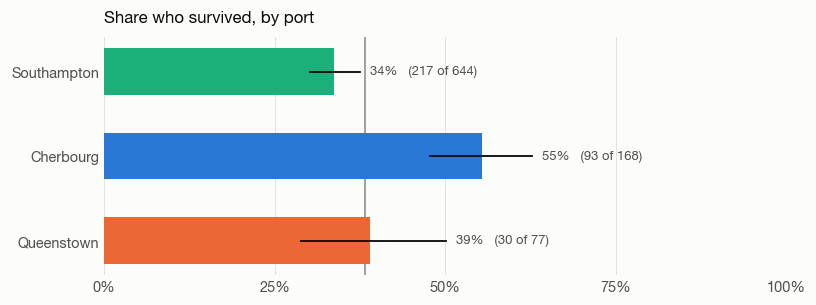

Chi-squared test of port against survival: chi-squared = 26.5 on 2 degrees of freedom, p = 1.8e-06. On its own, port is clearly related to survival.

In [2]:
g = tr.groupby("Embarked")["Survived"].agg(["size", "sum"]).reindex(PORTS)
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z ** 2 / n
    m = (p + z ** 2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return m - h, m + h
fig, ax = plt.subplots(figsize=(8, 2.8))
for i, p in enumerate(PORTS):
    n, k = g.loc[p, "size"], g.loc[p, "sum"]; lo, hi = wilson(k, n)
    ax.barh(i, k / n, height=0.55, color=PORT_C[p], zorder=3)
    ax.plot([lo, hi], [i, i], color=INK, linewidth=1.2, zorder=4)
    ax.text(hi + 0.015, i, f"{k / n:.0%}   ({int(k)} of {int(n)})", va="center", fontsize=8.5, color=INK2)
ax.axvline(y.mean(), color=MUTED, linewidth=1, zorder=2)
ax.set_yticks(range(3), [PORT_N[p] for p in PORTS]); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
clean(ax)
ax.set_title("Share who survived, by port", loc="left", fontsize=11, pad=10)
plt.show()
chi2, pval, _, _ = stats.chi2_contingency(pd.crosstab(tr["Embarked"], tr["Survived"]))
display(Markdown(f"Chi-squared test of port against survival: chi-squared = {chi2:.1f} on 2 degrees of freedom, p = {pval:.1e}. "
                 "On its own, port is clearly related to survival."))

The raw gap is large: Cherbourg's survival rate is 21 points above Southampton's. The intervals for Southampton and Queenstown overlap.

## 2. Who boarded where

Class and sex mix of each port's passengers. A port with more 1st class passengers or more women would survive at a higher rate even if port itself made no difference.

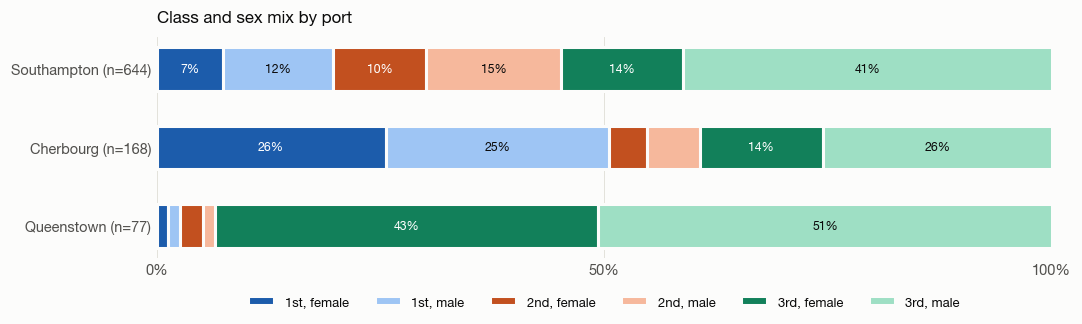

,Median ticket fare (GBP),Mean relatives aboard,Median age
Port,,,
Southampton,13.00,0.98,28.0
Cherbourg,29.70,0.75,29.0
Queenstown,7.75,0.60,27.0


In [3]:
groups = [("1", "female"), ("1", "male"), ("2", "female"), ("2", "male"), ("3", "female"), ("3", "male")]
glab = ["1st, female", "1st, male", "2nd, female", "2nd, male", "3rd, female", "3rd, male"]
shades = ["#1c5cab", "#9ec5f4", "#c2501f", "#f6b89c", "#12805a", "#9edfc4"]
mixm = pd.crosstab(tr["Embarked"], [tr["PclassS"], tr["Sex"]], normalize="index").reindex(PORTS)
fig, ax = plt.subplots(figsize=(10.5, 2.6))
left = np.zeros(3)
for (cl, sx), lab, col in zip(groups, glab, shades):
    v = mixm[(cl, sx)].values
    ax.barh(range(3), v, left=left, height=0.55, color=col, edgecolor=SURFACE, linewidth=2, label=lab, zorder=3)
    for i, (l_, w) in enumerate(zip(left, v)):
        if w >= 0.07:
            ax.text(l_ + w / 2, i, f"{w:.0%}", ha="center", va="center", fontsize=8, color="white" if col in shades[0::2] else INK)
    left += v
ax.set_yticks(range(3), [f"{PORT_N[p]} (n={int((tr['Embarked'] == p).sum())})" for p in PORTS]); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xticks([0, .5, 1], ["0%", "50%", "100%"])
clean(ax)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=6, frameon=False, fontsize=8.5)
ax.set_title("Class and sex mix by port", loc="left", fontsize=11, pad=10)
plt.show()
fare = tr.groupby("Embarked").agg(Fare=("Fare", "median"), Family=("Family", "mean"), Age=("Age", "median")).reindex(PORTS)
fare.index = [PORT_N[p] for p in PORTS]; fare.index.name = "Port"
display(fare.round(2).rename(columns={"Fare": "Median ticket fare (GBP)", "Family": "Mean relatives aboard", "Age": "Median age"}))

Cherbourg's passengers were richer: 51% 1st class, median fare 29.70 GBP against 13.00 at Southampton. Queenstown's were almost all 3rd class (94%) and paid least. Southampton carried the most 3rd class men (41% of its passengers), the group that survived worst. These differences alone would make Cherbourg look better.

## 3. Survival by port within class and sex

Each row is one class and sex group; each dot is a port, sized by the number of train passengers. If port made no difference, the dots in a row would sit together. Cells with fewer than 5 passengers are drawn hollow and should not be read as rates.

The **Cochran-Mantel-Haenszel test** compares two ports within each of the six groups and pools the results into one odds ratio, so the comparison is always like with like.

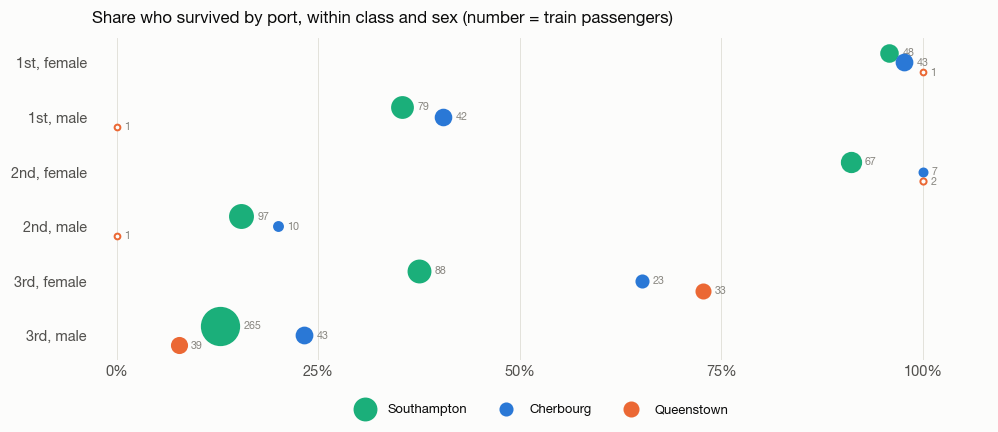

Comparison,Pooled odds ratio,CMH chi-squared,p
Cherbourg against Southampton,1.87,6.97,0.008
Queenstown against Southampton,1.92,3.43,0.064
Cherbourg against Queenstown,1.58,0.81,0.368


An odds ratio above 1 means better survival odds at the first port than at the second, within the same class and sex.

In [4]:
fig, ax = plt.subplots(figsize=(10.5, 3.8))
for i, (cl, sx) in enumerate(groups):
    for p in PORTS:
        m = tr[(tr["PclassS"] == cl) & (tr["Sex"] == sx) & (tr["Embarked"] == p)]
        if len(m) == 0:
            continue
        r = m["Survived"].mean(); off = {"S": -0.18, "C": 0, "Q": 0.18}[p]
        ax.scatter(r, i + off, s=12 + 2.2 * len(m), color=PORT_C[p] if len(m) >= 5 else SURFACE,
                   edgecolor=PORT_C[p], linewidth=1.3, zorder=3, label=PORT_N[p] if i == 4 else None)
        ax.annotate(str(len(m)), (r, i + off), xytext=(np.sqrt(12 + 2.2 * len(m)) / 2 + 3, 0), textcoords="offset points",
                    va="center", fontsize=7, color=MUTED)
ax.set_yticks(range(6), glab); ax.invert_yaxis()
ax.set_xlim(-0.03, 1.08); ax.set_xticks([0, .25, .5, .75, 1], ["0%", "25%", "50%", "75%", "100%"])
clean(ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False, fontsize=8.5)
ax.set_title("Share who survived by port, within class and sex (number = train passengers)", loc="left", fontsize=11, pad=10)
plt.show()

def cmh(a_port, b_port):
    num = den = 0; s_obs = s_exp = s_var = 0
    for cl, sx in groups:
        m = tr[(tr["PclassS"] == cl) & (tr["Sex"] == sx) & tr["Embarked"].isin([a_port, b_port])]
        n = len(m)
        if n < 2 or m["Embarked"].nunique() < 2:
            continue
        a = ((m["Embarked"] == a_port) & (m["Survived"] == 1)).sum(); b = ((m["Embarked"] == a_port) & (m["Survived"] == 0)).sum()
        c_ = ((m["Embarked"] == b_port) & (m["Survived"] == 1)).sum(); d = ((m["Embarked"] == b_port) & (m["Survived"] == 0)).sum()
        num += a * d / n; den += b * c_ / n
        r1, c1 = a + b, a + c_
        s_obs += a; s_exp += r1 * c1 / n
        s_var += r1 * (n - r1) * c1 * (n - c1) / (n ** 2 * (n - 1)) if n > 1 else 0
    chi = (abs(s_obs - s_exp) - 0.5) ** 2 / s_var
    return num / den, chi, stats.chi2.sf(chi, 1)
rows = []
for a_, b_ in [("C", "S"), ("Q", "S"), ("C", "Q")]:
    orr, chi, p = cmh(a_, b_)
    rows.append({"Comparison": f"{PORT_N[a_]} against {PORT_N[b_]}", "Pooled odds ratio": f"{orr:.2f}",
                 "CMH chi-squared": f"{chi:.2f}", "p": f"{p:.3f}"})
display(pd.DataFrame(rows).style.hide(axis="index"))
display(Markdown("An odds ratio above 1 means better survival odds at the first port than at the second, within the same class and sex."))

Within class and sex, much of the gap closes, but not all. 1st class women survived at 96 to 98% wherever they boarded. The clearest remaining differences are in 3rd class: women from Southampton survived at 38% against 65% from Cherbourg and 73% from Queenstown, and men from Cherbourg at 23% against 13% from Southampton. The pooled test still finds Cherbourg better than Southampton (odds ratio 1.87, p = 0.008); Queenstown against Southampton is borderline (1.92, p = 0.06).

## 4. Port odds ratios as controls are added

Logistic regression of survival on port, adding other features one step at a time. The dot is the odds ratio for Cherbourg (or Queenstown) against Southampton, with a 95% interval: 2 means twice the odds of survival, 1 means no difference. An interval crossing 1 means no detectable port effect at that step.

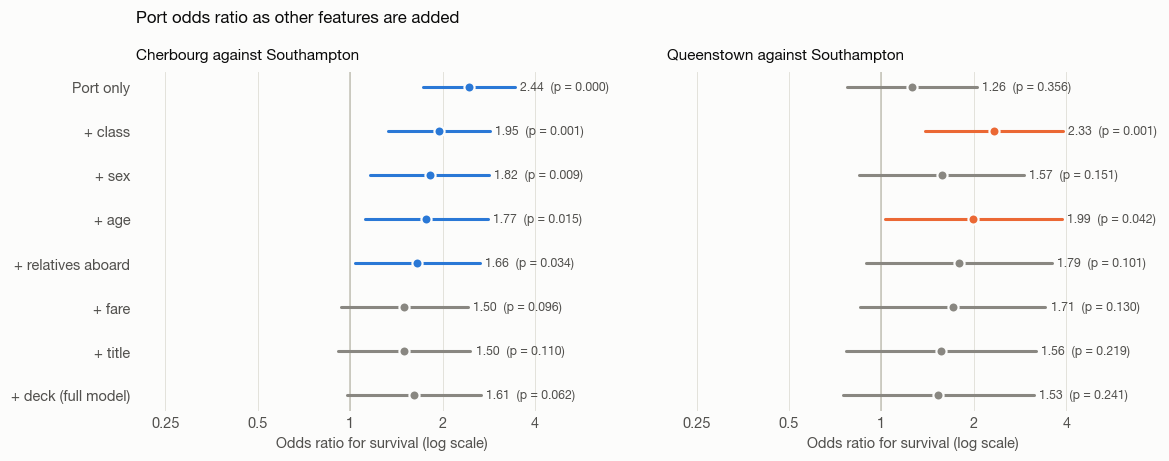

Coloured: the interval excludes 1. Grey: no detectable port effect at that step.

In [5]:
NUMC = ["AgeF", "AgeMissing", "SibSp", "Parch", "LogFare"]
def design(df, cats, nums, port=True, extra=None):
    X = pd.DataFrame(index=df.index)
    if port:
        X["C"] = (df["Embarked"] == "C").astype(float); X["Q"] = (df["Embarked"] == "Q").astype(float)
    for col in cats:
        X = X.join(pd.get_dummies(df[col], prefix=col, drop_first=True, dtype=float))
    for col in nums:
        X[col] = (df[col] - df[col].mean()) / df[col].std()
    if extra is not None:
        X = X.join(extra)
    return X

def fit(X, yv):
    m = LogisticRegression(C=1e6, max_iter=20000).fit(X.values, yv)
    p = m.predict_proba(X.values)[:, 1]
    ll = np.sum(yv * np.log(p) + (1 - yv) * np.log(1 - p))
    A = np.column_stack([np.ones(len(X)), X.values]); W = p * (1 - p)
    cov = np.linalg.pinv(A.T @ (A * W[:, None]))
    se = np.sqrt(np.diag(cov))[1:]
    return pd.DataFrame({"coef": m.coef_[0], "se": se}, index=X.columns), ll, X.shape[1]

STEPS = [("Port only", [], []),
         ("+ class", ["PclassS"], []),
         ("+ sex", ["PclassS", "Sex"], []),
         ("+ age", ["PclassS", "Sex"], ["AgeF", "AgeMissing"]),
         ("+ relatives aboard", ["PclassS", "Sex"], ["AgeF", "AgeMissing", "SibSp", "Parch"]),
         ("+ fare", ["PclassS", "Sex"], NUMC),
         ("+ title", ["PclassS", "Sex", "Title"], NUMC),
         ("+ deck (full model)", ["PclassS", "Sex", "Title", "DeckGroup"], NUMC)]
OR = []
for name, cats, nums in STEPS:
    co, ll, k = fit(design(tr, cats, nums), y)
    for p in ["C", "Q"]:
        b, s = co.loc[p, "coef"], co.loc[p, "se"]
        OR.append(dict(step=name, port=p, OR=np.exp(b), lo=np.exp(b - 1.96 * s), hi=np.exp(b + 1.96 * s),
                       p=2 * stats.norm.sf(abs(b / s))))
OR = pd.DataFrame(OR)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), sharey=True, gridspec_kw={"wspace": 0.08})
for ax, p in zip(axes, ["C", "Q"]):
    d = OR[OR["port"] == p].reset_index(drop=True)
    for i, r in d.iterrows():
        sig = r["lo"] > 1 or r["hi"] < 1
        col = PORT_C[p] if sig else MUTED
        ax.plot([r["lo"], r["hi"]], [i, i], color=col, linewidth=2, solid_capstyle="round", zorder=3)
        ax.scatter([r["OR"]], [i], s=44, color=col, edgecolor=SURFACE, linewidth=1.4, zorder=4)
        ax.text(r["hi"] * 1.04, i, f"{r['OR']:.2f}  (p = {r['p']:.3f})", va="center", fontsize=8, color=INK2)
    ax.axvline(1, color=AXIS, linewidth=1)
    ax.set_xscale("log"); ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0.25", "0.5", "1", "2", "4"]); ax.minorticks_off()
    ax.set_xlim(0.2, 8)
    clean(ax)
    ax.set_title(f"{PORT_N[p]} against Southampton", loc="left", fontsize=10, pad=8)
    ax.set_xlabel("Odds ratio for survival (log scale)")
axes[0].set_yticks(range(len(STEPS)), [s[0] for s in STEPS]); axes[0].invert_yaxis()
fig.suptitle("Port odds ratio as other features are added", x=0.125, ha="left", fontsize=11, y=1.02)
plt.show()
display(Markdown("Coloured: the interval excludes 1. Grey: no detectable port effect at that step."))

Cherbourg's odds ratio falls steadily as features are added, from 2.44 to about 1.5 to 1.6, and stops being significant once fare enters: part of what looked like a port effect was the higher fares paid at Cherbourg. Queenstown's odds ratio jumps once class is held fixed (to 2.33), because Queenstown's passengers were almost all 3rd class, then fades below significance as sex, family and fare enter.

## 5. Likelihood-ratio tests

Each test compares two nested models fitted to all 889 passengers. The chi-squared statistic is twice the gain in log-likelihood; p is the chance of a gain that large if the extra terms did nothing.

- **Port in the full model**: full model with and without port.
- **Port by class**: does port matter differently for 3rd class than for 1st and 2nd?
- **Port by sex**: does port matter differently for women than for men?

In [6]:
FULL_C, FULL_N = ["PclassS", "Sex", "Title", "DeckGroup"], NUMC
_, ll0, k0 = fit(design(tr, FULL_C, FULL_N, port=False), y)
_, ll1, k1 = fit(design(tr, FULL_C, FULL_N), y)
third = (tr["Pclass"] == 3).astype(float); fem = (tr["Sex"] == "female").astype(float)
ix_cls = pd.DataFrame({"C x 3rd": (tr["Embarked"] == "C") * third, "Q x 3rd": (tr["Embarked"] == "Q") * third})
ix_sex = pd.DataFrame({"C x female": (tr["Embarked"] == "C") * fem, "Q x female": (tr["Embarked"] == "Q") * fem})
_, ll2, k2 = fit(design(tr, FULL_C, FULL_N, extra=ix_cls), y)
_, ll3, k3 = fit(design(tr, FULL_C, FULL_N, extra=ix_sex), y)
co4, ll4, k4 = fit(design(tr, FULL_C, FULL_N, extra=ix_cls.join(ix_sex)), y)
rows = []
for name, la, lb, ka, kb in [("Port in the full model", ll0, ll1, k0, k1), ("Port by class", ll1, ll2, k1, k2),
                              ("Port by sex", ll1, ll3, k1, k3), ("Port by class and by sex", ll1, ll4, k1, k4)]:
    chi = 2 * (lb - la); df = kb - ka
    rows.append({"Test": name, "Extra terms": df, "Chi-squared": f"{chi:.2f}", "p": f"{stats.chi2.sf(chi, df):.3f}"})
display(pd.DataFrame(rows).style.hide(axis="index"))
ci = co4.loc[["C", "C x 3rd", "C x female"]].copy()
ci["Odds ratio"] = np.exp(ci["coef"]).round(2)
ci["95% interval"] = [f"{np.exp(b - 1.96 * s):.2f} to {np.exp(b + 1.96 * s):.2f}" for b, s in zip(ci["coef"], ci["se"])]
ci.index = ["Cherbourg (1st and 2nd class men)", "Cherbourg x 3rd class", "Cherbourg x female"]
ci.index.name = "Term, model with both interactions"
display(ci[["Odds ratio", "95% interval"]])
display(Markdown("Cherbourg terms from the model with both interactions. Queenstown terms are not shown: only 5 Queenstown "
                 "train passengers were outside 3rd class, so its terms cannot be estimated (intervals span 0.02 to 36)."))

Test,Extra terms,Chi-squared,p
Port in the full model,2,4.10,0.129
Port by class,2,0.81,0.668
Port by sex,2,2.61,0.271
Port by class and by sex,4,3.39,0.494


,Odds ratio,95% interval
"Term, model with both interactions",,
Cherbourg (1st and 2nd class men),1.30,0.64 to 2.64
Cherbourg x 3rd class,1.56,0.56 to 4.36
Cherbourg x female,1.04,0.37 to 2.96


Cherbourg terms from the model with both interactions. Queenstown terms are not shown: only 5 Queenstown train passengers were outside 3rd class, so its terms cannot be estimated (intervals span 0.02 to 36).

None of the tests is significant. Adding port to the full model improves its fit no more than chance would (p = 0.13), and allowing port to work differently by class or by sex adds nothing (p = 0.67 and 0.27).

## 6. Does port improve held-out accuracy?

The full model with and without port, 10-fold cross-validation repeated 10 times, regularised logistic regression (C = 1) as in the earlier notebooks. p is corrected for the overlap between folds.

In [7]:
CAT = ["PclassS", "Sex", "Title", "DeckGroup"]; NUM = ["Age", "AgeMissing", "SibSp", "Parch", "LogFare"]
def pipe(cats):
    pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cats),
                             ("n", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM)])
    return make_pipeline(pre, LogisticRegression(max_iter=5000))
tr["Third_C"] = ((tr["Pclass"] == 3) & (tr["Embarked"] == "C")).astype(str)
tr["Third_Q"] = ((tr["Pclass"] == 3) & (tr["Embarked"] == "Q")).astype(str)
tr["Fem_C"] = ((tr["Sex"] == "female") & (tr["Embarked"] == "C")).astype(str)
tr["Fem_Q"] = ((tr["Sex"] == "female") & (tr["Embarked"] == "Q")).astype(str)
VAR = {"Without port": CAT, "With port": CAT + ["Embarked"],
       "With port and port by class": CAT + ["Embarked", "Third_C", "Third_Q"],
       "With port and port by sex": CAT + ["Embarked", "Fem_C", "Fem_Q"]}
splits = list(RepeatedStratifiedKFold(n_splits=10, n_repeats=10, random_state=0).split(tr, y))
acc = {k: np.array([np.mean((pipe(v).fit(tr.iloc[a], y[a]).predict_proba(tr.iloc[b])[:, 1] >= 0.5) == y[b])
                    for a, b in splits]) for k, v in VAR.items()}
K = len(splits); base = acc["Without port"]
rows = []
for k, v in acc.items():
    if k == "Without port":
        rows.append({"Model": k, "Accuracy": f"{100 * v.mean():.1f}%", "Change (points)": "", "p": ""}); continue
    d = v - base; se = np.sqrt((1 / K + 1 / 9) * d.var(ddof=1))
    rows.append({"Model": k, "Accuracy": f"{100 * v.mean():.1f}%", "Change (points)": f"{100 * d.mean():+.1f}",
                 "p": f"{2 * stats.t.sf(abs(d.mean() / se), K - 1):.2f}"})
display(pd.DataFrame(rows).style.hide(axis="index"))

Model,Accuracy,Change (points),p
Without port,82.5%,,
With port,82.9%,+0.5,0.39
With port and port by class,83.0%,+0.6,0.28
With port and port by sex,83.0%,+0.5,0.38


Port moves held-out accuracy by about half a point, well within the noise (p of 0.28 to 0.39). Interactions with class or sex do not help either.

## 7. Held-out residuals by port

A model without port (the full model above, port removed) predicts each passenger's survival from 10-fold cross-validation repeated 10 times, averaged. The residual is survived minus predicted: a positive mean means a port's passengers did better than everything else about them predicts.

The test is run over passengers, and again over parties (passengers linked by a shared ticket or family), each counted once, because a single large family can move a port's mean on its own. p is from 4,000 random reshuffles of the residuals across ports.

In [8]:
P_ = np.zeros((10, len(tr)))
for i, (a, b) in enumerate(splits):
    P_[i // 10, b] = pipe(CAT).fit(tr.iloc[a], y[a]).predict_proba(tr.iloc[b])[:, 1]
tr["Resid"] = y - P_.mean(axis=0)
rng = np.random.default_rng(0)
def perm(vals, labs, perms=4000):
    labs = np.asarray(labs); vals = np.asarray(vals)
    def stat(v):
        return sum((labs == p).sum() * (v[labs == p].mean() - v.mean()) ** 2 for p in PORTS)
    obs = stat(vals); null = np.array([stat(rng.permutation(vals)) for _ in range(perms)])
    return (np.sum(null >= obs) + 1) / (perms + 1)
party = tr.groupby("Party").agg(Resid=("Resid", "mean"), Port=("Embarked", lambda s: s.mode().iloc[0]))
p_pass, p_party = perm(tr["Resid"], tr["Embarked"]), perm(party["Resid"], party["Port"])
rows = []
for p in PORTS:
    m = tr[tr["Embarked"] == p]; mp = party[party["Port"] == p]
    rows.append({"Port": PORT_N[p], "Passengers": len(m), "Survived": f"{m['Survived'].mean():.0%}",
                 "Model without port expected": f"{(m['Survived'] - m['Resid']).mean():.0%}",
                 "Mean residual": f"{m['Resid'].mean():+.3f}", "Parties": len(mp), "Mean residual by party": f"{mp['Resid'].mean():+.3f}"})
display(pd.DataFrame(rows).style.hide(axis="index"))
display(Markdown(f"Reshuffle test of port against residuals: p = {p_pass:.3f} over passengers, p = {p_party:.3f} over parties."))
sub = tr.groupby(["Embarked", "PclassS", "Sex"]).agg(n=("Resid", "size"), resid=("Resid", "mean"), surv=("Survived", "mean")).reset_index()
sub = sub[sub["n"] >= 10]
sub["Group"] = sub["PclassS"].map({"1": "1st", "2": "2nd", "3": "3rd"}) + ", " + sub["Sex"]
sub["Port"] = sub["Embarked"].map(PORT_N)
display(sub[["Port", "Group", "n", "surv", "resid"]].rename(columns={"n": "Passengers", "surv": "Survived", "resid": "Mean residual"})
        .assign(Survived=lambda d: (100 * d["Survived"]).round(0).astype(int).astype(str) + "%", **{"Mean residual": lambda d: d["Mean residual"].map("{:+.3f}".format)})
        .style.hide(axis="index"))

Port,Passengers,Survived,Model without port expected,Mean residual,Parties,Mean residual by party
Southampton,644,34%,35%,-0.015,257,-0.016
Cherbourg,168,55%,51%,+0.041,63,+0.087
Queenstown,77,39%,36%,+0.032,37,-0.020


Reshuffle test of port against residuals: p = 0.136 over passengers, p = 0.056 over parties.

Port,Group,Passengers,Survived,Mean residual
Cherbourg,"1st, female",43,98%,+0.041
Cherbourg,"1st, male",42,40%,+0.004
Cherbourg,"2nd, male",10,20%,-0.064
Cherbourg,"3rd, female",23,65%,-0.002
Cherbourg,"3rd, male",43,23%,+0.105
Queenstown,"3rd, female",33,73%,+0.108
Queenstown,"3rd, male",39,8%,-0.024
Southampton,"1st, female",48,96%,+0.026
Southampton,"1st, male",79,35%,-0.032
Southampton,"2nd, female",67,91%,+0.103


A model without port slightly underpredicts Cherbourg (by 4 points over passengers, 9 points over parties) and overpredicts Southampton by about 2 points. Neither test is significant at 0.05: p = 0.14 over passengers, p = 0.06 over parties. The largest leftover gap is not a port as a whole but one group within it: 3rd class women from Southampton, overpredicted by 16 points across 88 passengers.